# 04 - New Opportunity & Solution: Wholesale Discount Governance
*Not requested in the case briefs - found by looking for where profit leaks.*

**Structure:** Problem -> Evidence -> Root cause -> Business impact -> Proposed solution -> Technical approach -> Expected value.

In [1]:
import sys, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src")); sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")
import pandas as pd
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30); pd.set_option("display.float_format", "{:,.3f}".format)
import analysis as A, modeling as M, visuals as V
from utils import fmt_egp, fmt_pct, fmt_int

In [2]:
import run_pipeline as RP
d = A.load_all()
R = RP.build_results(d)
s = d["sales"]

In [3]:
w = R['wholesale']

## 1. Problem
Wholesale generates 85% of revenue but earns only 11.9% margin, versus 35-37% in retail and online. Why?

In [4]:
R['channel_scorecard'][['Channel','Net_Share','GP_Share','Gross_Margin','Avg_Discount','GP_per_Unit']]

,Channel,Net_Share,GP_Share,Gross_Margin,Avg_Discount,GP_per_Unit
0,Online,0.077,0.175,0.349,0.088,114.598
1,Retail,0.070,0.168,0.370,0.056,126.131
2,Wholesale,0.853,0.657,0.119,0.326,28.904


## 2. Evidence

### 2.1 Unit costs are the same in every channel - the gap is price (discount)

In [5]:
s.assign(Unit_COGS=s.Estimated_COGS_EGP / s.Quantity).groupby('Channel').Unit_COGS.mean().to_frame('Avg unit COGS (EGP)')

,Avg unit COGS (EGP)
Channel,
Online,213.897
Retail,214.503
Wholesale,214.767


### 2.2 Wholesale discounts are 28-38% with no link to order size

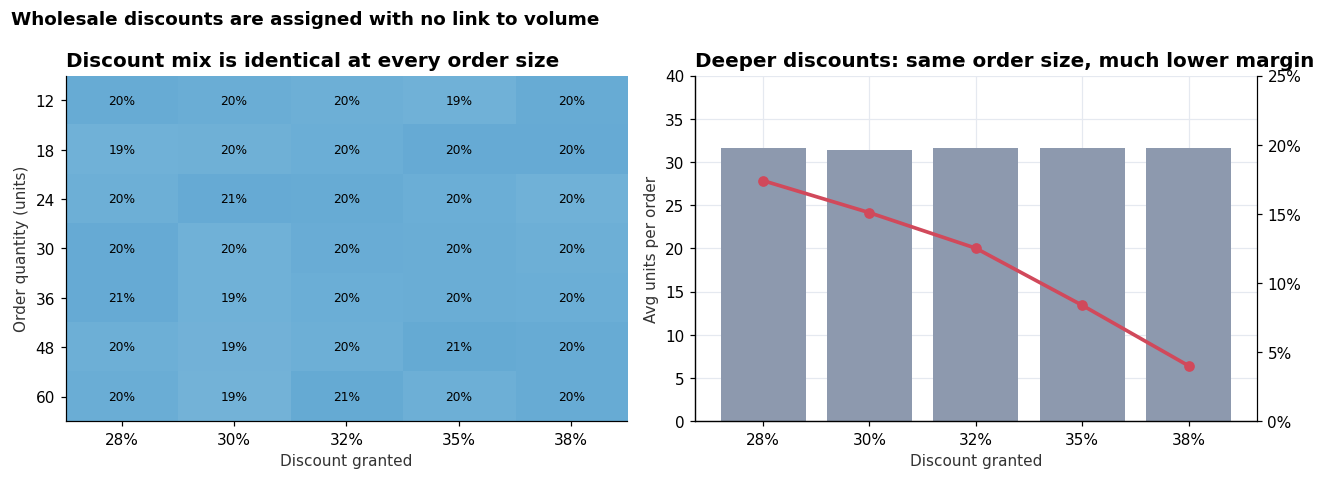

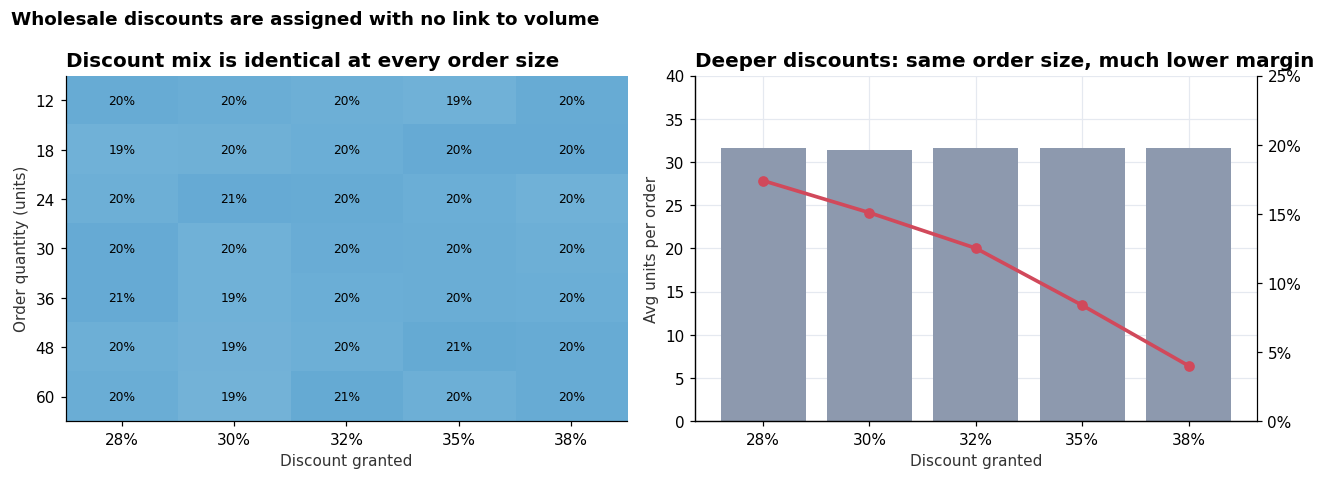

In [6]:
V.discount_vs_quantity(w)

Order quantity ranges 12-60 units; every discount level (28/30/32/35/38%) appears in ~20% of orders **at every order size**. A 60-unit order is as likely to get 28% as a 12-unit order is to get 38%.

### 2.3 Margin collapses at deep discounts; 4,876 invoices lose money

In [7]:
w.groupby('Discount_Pct').agg(Lines=('Invoice_ID','count'), Avg_Units=('Quantity','mean'), Gross_Margin=('Gross_Margin_Pct','mean'), Loss_Making_Lines=('Is_Loss_Making','sum'))

,Lines,Avg_Units,Gross_Margin,Loss_Making_Lines
Discount_Pct,,,,
0.280,9369,31.646,0.174,0
0.300,9225,31.393,0.151,122
0.320,9380,31.641,0.125,537
0.350,9363,31.682,0.084,924
0.380,9335,31.662,0.040,3293


In [8]:
print(f"Break-even discount: {s.Breakeven_Discount_Pct.mean():.1%} on average; loss-making invoices: {s.Is_Loss_Making.sum():,} = EGP {s.loc[s.Is_Loss_Making,'Gross_Profit_EGP'].sum():,.0f}")

Break-even discount: 40.5% on average; loss-making invoices: 4,876 = EGP -1,374,656


### 2.4 Do discounts buy volume or loyalty? (price-response tests)

In [9]:
R['price_response']

,Test,Coefficient,CI_Low,CI_High,p_value,Rows
0,Order size: pooled (log qty per +1pt discount),0.000,-0.001,0.001,0.582,46672
1,Order size: within-customer deviation,0.000,-0.001,0.001,0.653,45896
2,Days to customer's next order (per +1pt discount),-0.041,-0.097,0.015,0.149,43918


A 1-point deeper discount changes order size by **+0.03%** (95% CI -0.08% to +0.14%, p=0.58); within-customer comparison p=0.65; time to the customer's next order p=0.15. **Deeper discounts buy nothing measurable.**

### 2.5 Can anything predict the discount? (diagnostic ML model)
**Target:** discount % per wholesale line. **Features (known at quote time):** quantity, list price, product family, COGS ratio, customer's prior orders / prior spend / prior mean discount / tenure, governorate, payment method. **Split:** time-based - train before 2026-01-01 (34,246 lines), test after (12,426). **Baseline:** training mean. **Model:** gradient boosting. **Explainability:** permutation importance.

In [10]:
dg = R['discount_diagnostic']
pd.DataFrame({'R2': [dg['baseline_r2'], dg['model_r2']], 'MAE (pts)': [dg['baseline_mae']*100, dg['model_mae']*100]}, index=['Baseline (mean)', 'Gradient boosting'])

,R2,MAE (pts)
Baseline (mean),-0.000,3.131
Gradient boosting,0.008,3.098


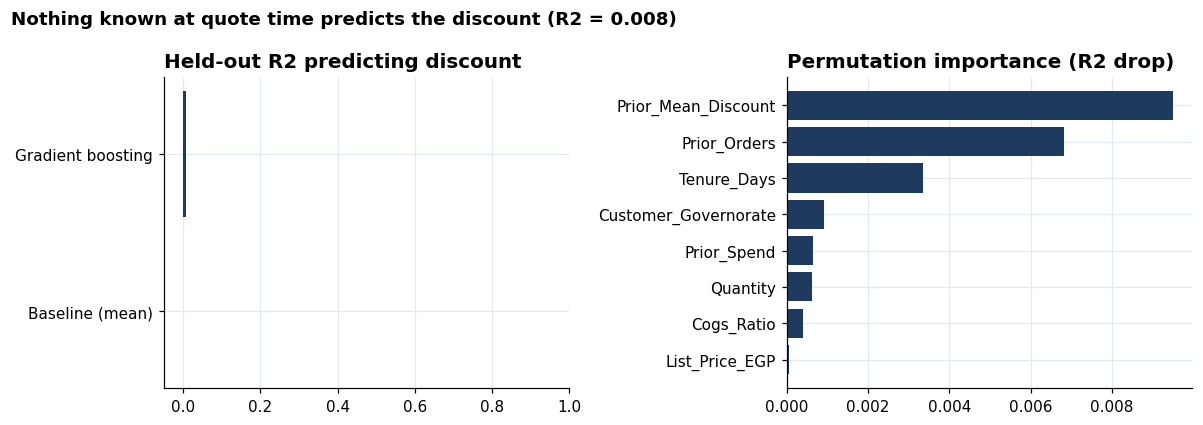

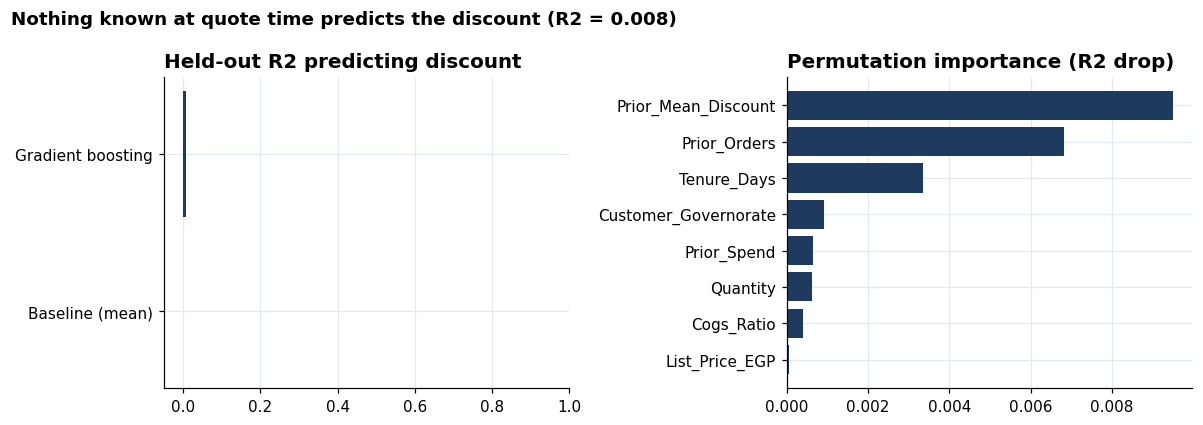

In [11]:
V.diagnostic_importance_chart(dg)

**R2 = 0.008:** a flexible model with 10 features cannot predict the discount. It is not driven by volume, customer history, product or cost - it is **discretionary and unmanaged**.

## 3. Root cause
There is no discount policy or approval control: reps choose a discount in the 28-38% band independent of volume, margin or customer value, and nothing stops sub-cost quotes. Because the price-response is ~0, the extra discount is pure margin leakage.

In [12]:
R['leakage_product']

,Product_Family,Lines,Net_Sales,Gross_Profit,Leakage_EGP,Leakage_Pct_of_GP
1,Pajamas/Homewear,33016,"231,783,412.320","26,722,806.560","9,435,449.160",0.353
2,Sweatshirts,5614,"65,679,197.760","9,593,143.540","2,640,865.680",0.275
0,Kids Sets,3671,"31,166,688.000","3,400,835.120","1,296,048.000",0.381
3,T-Shirts,4371,"30,731,817.600","2,918,257.160","1,265,774.400",0.434


## 4. Business impact

In [13]:
pd.Series({
 'Discount given (wholesale, 3y)': fmt_egp(R['discount_leakage'].set_index('Channel').loc['Wholesale','Discount_Given']),
 'Share of pre-discount margin given away': fmt_pct(R['discount_leakage'].set_index('Channel').loc['Wholesale','Share_of_Margin_Given_Away']),
 'Loss-making invoices': f"{s.Is_Loss_Making.sum():,}",
 'Loss on those invoices': fmt_egp(s.loc[s.Is_Loss_Making,'Gross_Profit_EGP'].sum()),
 'Wholesale margin today': fmt_pct(R['channel_scorecard'].set_index('Channel').loc['Wholesale','Gross_Margin'])}, name='Impact').to_frame()

,Impact
"Discount given (wholesale, 3y)",EGP 173.9M
Share of pre-discount margin given away,80.3%
Loss-making invoices,"4,876"
Loss on those invoices,-EGP 1.4M
Wholesale margin today,11.9%


## 5. Proposed solution - a Wholesale Deal Desk
1. **Phase 1 - Volume-tiered discount cap:** 12-23 units max 28%, 24-47 units max 30%, 48+ units max 32%. Bigger orders earn a *higher* ceiling - the logic that is missing today.
2. **Phase 2 - Margin floor 15%:** any quote that would push gross margin under 15% (product-specific, because COGS/price ratios differ) routes to approval.
3. **Approval route:** within cap and margin >= 15% -> auto; margin >= 8% -> sales manager; below 8% -> director; below cost -> rejected.
4. **Monitoring:** monthly discount-vs-volume and margin report; leakage by rep/customer.

## 6. Technical approach - simulation on three years of real invoices

In [14]:
pt = R['policy_table']
pt[pt.Volume_Loss_On_Repriced.isin([0, 0.1, 0.2])][['Policy','Volume_Loss_On_Repriced','Share_Lines_Repriced','New_GM','Loss_Making_Lines_After','GP_Uplift','GP_Uplift_per_Year']]

,Policy,Volume_Loss_On_Repriced,Share_Lines_Repriced,New_GM,Loss_Making_Lines_After,GP_Uplift,GP_Uplift_per_Year
0,Flat cap 30%,0.000,0.602,0.156,540,"16,044,166.200","5,351,718.452"
2,Flat cap 30%,0.100,0.602,0.157,540,"12,645,846.377","4,218,169.305"
3,Flat cap 30%,0.200,0.602,0.157,540,"9,247,526.554","3,084,620.159"
4,Volume-tiered cap,0.000,0.597,0.153,695,"14,638,137.240","4,882,721.120"
6,Volume-tiered cap,0.100,0.597,0.153,695,"11,592,364.582","3,866,768.186"
7,Volume-tiered cap,0.200,0.597,0.154,695,"8,546,591.924","2,850,815.251"
8,Margin floor 15%,0.000,0.640,0.169,0,"21,826,170.425","7,280,373.286"
10,Margin floor 15%,0.100,0.640,0.170,0,"18,176,255.447","6,062,901.646"
11,Margin floor 15%,0.200,0.640,0.172,0,"14,526,340.470","4,845,430.006"
12,Tiered cap + margin floor,0.000,0.775,0.179,0,"26,374,469.911","8,797,511.539"


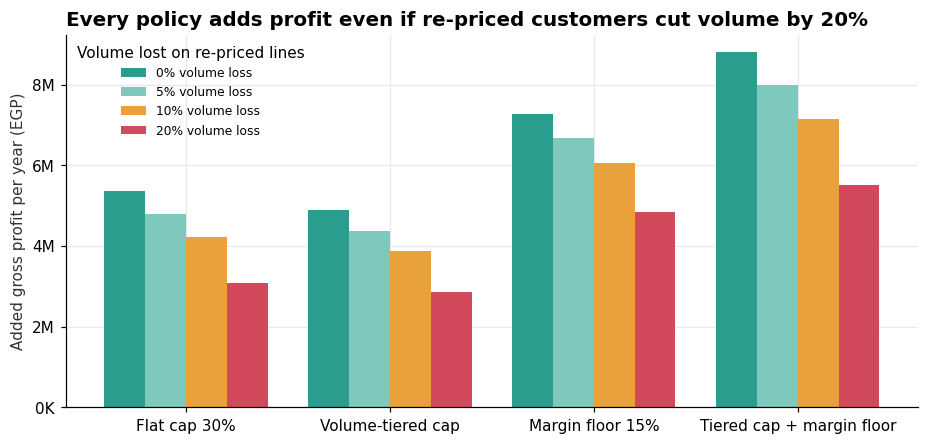

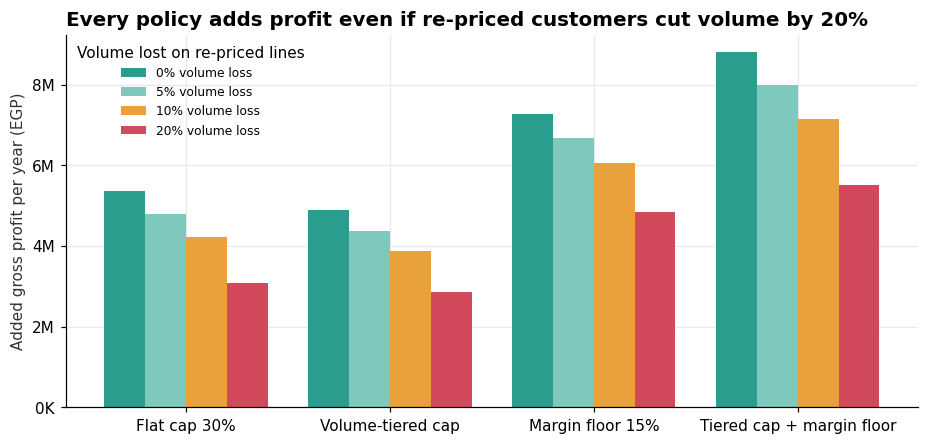

In [15]:
V.policy_uplift_chart(R['policy_table'])

In [16]:
pd.Series(R['breakeven_volume_loss'], name='Volume loss on re-priced lines at which GP uplift = 0').to_frame()

,Volume loss on re-priced lines at which GP uplift = 0
Flat cap 30%,0.472
Volume-tiered cap,0.481
Margin floor 15%,0.598
Tiered cap + margin floor,0.536


Re-pricing means: new discount = min(old discount, cap). Sensitivity: a share of the units on re-priced lines is assumed lost (0-20%), with COGS removed with those units.
**Reading:** Phase 1 re-prices 60% of invoices and lifts wholesale margin from 11.9% to 15.3%; it stays profitable until re-priced customers cut volume by **48%** - against an observed price response of ~0.

### Deal-desk prototype (callable function)

In [17]:
uc = A.unit_costs(s)
quotes = [("P005", 36, 0.38), ("P005", 60, 0.30), ("P032", 24, 0.30), ("P032", 12, 0.28), ("P051", 48, 0.35)]
pd.DataFrame([M.evaluate_quote(p, q, disc, d['products'], uc) for p, q, disc in quotes])[['Product_ID','Quantity','Quoted_Discount','Tier_Cap','Margin_Floor_Cap','Counter_Offer_Discount','Gross_Margin','Order_GP_EGP','Order_GP_at_Counter_EGP','Status']]

,Product_ID,Quantity,Quoted_Discount,Tier_Cap,Margin_Floor_Cap,Counter_Offer_Discount,Gross_Margin,Order_GP_EGP,Order_GP_at_Counter_EGP,Status
0,P005,36,0.380,0.300,0.259,0.259,-0.016,-123.930,"1,392.581",REJECT - below cost
1,P005,60,0.300,0.320,0.259,0.259,0.100,"1,463.850","2,320.968",MANAGER APPROVAL
2,P032,24,0.300,0.300,0.228,0.228,0.062,571.843,"1,526.710",DIRECTOR APPROVAL - margin under 8%
3,P032,12,0.280,0.280,0.228,0.228,0.088,417.682,763.355,MANAGER APPROVAL
4,P051,48,0.350,0.320,0.275,0.275,0.052,625.412,"2,025.916",DIRECTOR APPROVAL - margin under 8%


The policy parameters are saved to `outputs/models/deal_desk_policy.json`; the diagnostic model to `outputs/models/discount_diagnostic_hgb.joblib`. The dashboard exposes the same `evaluate_quote` function as an interactive quote checker.

## 7. Expected value

In [18]:
R['value_at_stake'][R['value_at_stake'].Action.str.startswith('1')][['Action','Low','Base','High','Assumption']]

,Action,Low,Base,High,Assumption
0,1. Wholesale discount governance - Phase 1: vo...,"2,850,815.251","3,866,768.186","4,882,721.120",Volume loss on re-priced lines 20% / 10% / 0%;...
1,1b. Wholesale discount governance - Phase 2: m...,"2,665,483.719","3,290,137.069","3,914,790.418","Incremental to Phase 1, same volume-loss assum..."


In [19]:
t = R['policy_table']
base = t[(t.Policy=='Volume-tiered cap') & (t.Volume_Loss_On_Repriced==0.1)].iloc[0]
print(f"Phase 1 (10% volume loss on re-priced lines): +{fmt_egp(base.GP_Uplift_per_Year)} GP / year -> wholesale margin {base.Old_GM:.1%} -> {base.New_GM:.1%}")
print(f"As a share of FY26 group gross profit: {base.GP_Uplift_per_Year / R['kpi_fy'].set_index('Fiscal_Year').Gross_Profit['FY26']:.0%}")

Phase 1 (10% volume loss on re-priced lines): +EGP 3.9M GP / year -> wholesale margin 11.9% -> 15.3%
As a share of FY26 group gross profit: 17%


**Expected value:** Phase 1 adds **EGP 2.9-4.9M gross profit per year (base 3.9M; +17% of FY26 gross profit)**; Phase 2 a further EGP 2.7-3.9M. Together EGP 5.5-8.8M per year (+24-38%).
**Risks and mitigations:** (1) some wholesale customers may push back - mitigate with tiered caps that reward volume and a 90-day phase-in; (2) price-response estimates come from the historical range 28-38% - monitor monthly and stop if volume loss exceeds the break-even; (3) COGS is an estimate, not a costed standard - validate with finance before rollout.

**Next step:** pilot Phase 1 with the 25 customers with the highest leakage (`leakage_customer` table) for 90 days.